In [2]:
import json
import os

import numpy as np
import matplotlib.pyplot as plt

In [3]:
with open("/home/klymy/data/cam4_revB/train_val_holdout_subsets_batches_testAccuracy.json", "r") as f:
    data = json.load(f)

In [4]:
def get_heights(data):
    heights = {}
    for k, v in data.items():
        tmp_heights = []
        for i in v:
            if "___" in i:
                # Skip entries with '___' in the filename
                continue
            try:
                tmp_heights.append(int(i.split("cam_")[-1].split("_")[0]))
            except ValueError:
                tmp_heights.append(int(i.split("_H")[-1].split("_")[0]))

        heights[k] = tmp_heights
    return heights

In [7]:
heights = get_heights(data)
heights["holdout"] = [i if i > 100 else i + 200 for i in heights["holdout"]]

Text(0.5, 0.98, 'Height Distribution in CAM4 RevB BASELINE TEST (ITERATION 1) Datasets')

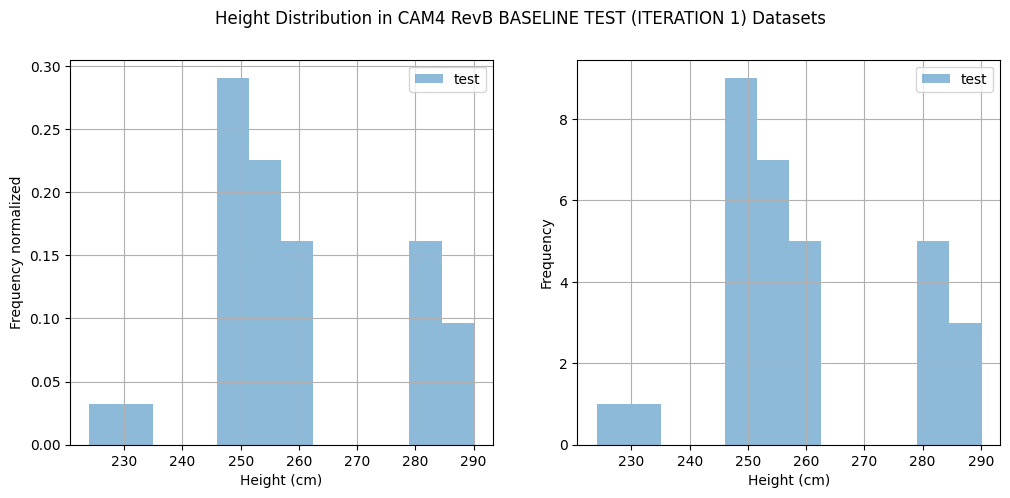

In [9]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
# plt.hist(heights["train"], bins=12, alpha=0.5, label="train", weights=np.ones(len(heights["train"])) / len(heights["train"]))
# plt.hist(heights["val"], bins=12, alpha=0.5, label="val", weights=np.ones(len(heights["val"])) / len(heights["val"]))
plt.hist(heights["holdout"], bins=12, alpha=0.5, label="test", weights=np.ones(len(heights["holdout"])) / len(heights["holdout"]))
plt.xlabel("Height (cm)")
plt.ylabel("Frequency normalized")
plt.grid()

plt.legend()

plt.subplot(1, 2, 2)
# plt.hist(heights["train"], bins=12, alpha=0.5, label="train")
# plt.hist(heights["val"], bins=12, alpha=0.5, label="val")
plt.hist(heights["holdout"], bins=12, alpha=0.5, label="test")
plt.xlabel("Height (cm)")
plt.ylabel("Frequency")
plt.grid()
plt.legend()


plt.suptitle("Height Distribution in CAM4 RevB BASELINE TEST (ITERATION 1) Datasets")

In [12]:
len(heights["train"]), len(heights["val"]), len(heights["holdout"])

(13286, 1474, 146)

In [13]:
len(heights["train"]) + len(heights["val"]) + len(heights["holdout"])

14906

In [9]:
# (17993, 1996, 146)